# Приоритизация обращений - прогноз успешного целевого действия

**Задача.** Для каждого обращения (`lead_id`) в момент назначения оценить вероятность успешного
целевого действия в ближайшие 5 дней. Итоговый `score ∈ [0, 1]` используется для **ранжирования
внутри дня**: чем выше, тем перспективнее обращение.

**Метрика.** Daily Average Precision - Average Precision считается отдельно по каждой дате назначения,
затем усредняется по дням.
---

## Как я решал задачу

1. **EDA и аудит утечки.** Проверил временную структуру (test идёт строго после train), дисбаланс
   таргета (~21% позитивов), и главное  - что часть событий в `events.csv` датирована *после* назначения.
   Такие события отбрасываются: любой признак из событий строится только на `event_ts < assignment_ts`.
2. **Feature engineering.** Пять блоков признаков (подробно ниже): табличные конверсии/тренды,
   агрегаты событий по временным окнам, price-fit + воронка намерения, форма последних 5 событий и
   развёртка категориальных полей событий (`ctx_seq`, `src_slot`, `event_type x ctx_seq`).
   Последний блок дал основной прирост.
3. **Отбор признаков.** Корреляционный отсев дубликатов (`|r|>0.95`) -> ранжирование по SHAP ->
   forward-отбор: добавляем признаки по убыванию важности и берём число признаков с максимумом
   Daily AP на кросс-валидации.
4. **Модели.** Ансамбль **CatBoost + XGBoost** (градиентный бустинг с разной механикой -> разные ошибки).
   Предсказания смешиваются по **внутридневным перцентильным рангам**.
5. **Валидация.** **Expanding-window** по датам: обучаемся на прошлом, валидируемся на следующих 3 днях.
   Схема повторяет боевой сценарий (скрытый test идёт после train), поэтому оценка не оптимистична.


**Про валидацию.** Сначала я оценивал модели на **2 временных фолдах** (обучение < 60% дат — валидация 60–80%;
обучение < 80% — валидация 80–100%). Такая схема даёт всего две точки, поэтому
я перешёл на **expanding-window**: обучение всегда на прошлом, валидация на следующих 3 днях, а обучающее окно
расширяется по мере движения по датам. Это даёт более стабильную оценку Daily AP.

Использование всех  признаков без отсева дало результат хуже, чем отобранные с **SHAP**, - избыточный шум размывал модель.
Выявление top‑N и forward/backward отбор по SHAP показали, что оптимум лежит в диапазоне 65-100 признаков.

## Ограничения задачи
Без LLM/внешних API, без ручной разметки test, без хардкода под конкретные `lead_id`.
Использованы только open-source библиотеки (CatBoost, XGBoost, SHAP, scikit-learn, pandas), разворачиваемые
локально. Гиперпараметры подобраны оффлайн через Optuna и зашиты в код (см. раздел с моделями).

## 0. Окружение и воспроизводимость

**Как запустить.** Положите `train.csv`, `test.csv`, `events.csv` в папку `./data` рядом с ноутбуком
(или укажите путь через переменную окружения `LEAD_CHALLENGE_DIR`) и выполните ячейки.
Результат - файл `submission.csv` с колонками `lead_id`, `score`.

**Версии библиотек** ниже, запускал на Python=3.11.6

In [4]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import catboost as cb
import xgboost as xgb
import shap
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 250)
plt.rcParams["figure.dpi"] = 110


TARGET = "target"
NON_FEATURE_COLUMNS = {"lead_id", "user_id", "assignment_ts", "assignment_date", TARGET, "split"}
RANDOM_STATE = 42
CV_SEEDS = [42]                # для отбора и CV
FINAL_SEEDS = [42, 7, 2026]    # для финального submission — усреднение по 3 сидам
CORR_THRESHOLD = 0.95          


def resolve_data_dir() -> Path:
    candidates = []
    env = os.getenv("LEAD_CHALLENGE_DIR")
    if env:
        candidates.append(Path(env))
    candidates += [Path("data"), Path("./lead_prioritization_challenge/data"), Path("../data")]
    for c in candidates:
        if all((c / f).exists() for f in ("train.csv", "test.csv", "events.csv")):
            return c
    raise FileNotFoundError(
        "Не найдены train.csv/test.csv/events.csv. Положите их в ./data "
        "или задайте путь через переменную окружения LEAD_CHALLENGE_DIR."
    )


DATA_DIR = resolve_data_dir()
#print("данные:", DATA_DIR.resolve())
#print("catboost", cb.__version__, "| xgboost", xgb.__version__, "| shap", shap.__version__)

## 1. Загрузка данных и метрика

Загружаем три таблицы и приводим временные колонки к `datetime`. Здесь же определяем **точную метрику
Daily AP** (её же используем во всей валидации) и вспомогательную функцию перцентильного ранга внутри дня.

In [5]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
events = pd.read_csv(DATA_DIR / "events.csv")

for df in (train, test):
    df["assignment_ts"] = pd.to_datetime(df["assignment_ts"])
    df["assignment_date"] = pd.to_datetime(df["assignment_date"])
events["event_ts"] = pd.to_datetime(events["event_ts"])


def daily_average_precision(dates, y_true, scores) -> float:
    """Daily Average Precision: AP внутри каждой даты назначения, затем среднее по дням.

    Дни без положительных примеров пропускаем (AP для них не определён).
    """
    frame = pd.DataFrame({"d": np.asarray(dates), "y": np.asarray(y_true), "s": np.asarray(scores)})
    per_day = [average_precision_score(g["y"], g["s"]) for _, g in frame.groupby("d") if g["y"].sum() > 0]
    return float(np.mean(per_day))


def daily_rank(dates, scores) -> np.ndarray:
    """Перцентильный ранг скора внутри дня.

    Daily AP зависит только от порядка внутри дня, поэтому модели в ансамбле смешиваем именно по
    внутридневным рангам.
    """
    s = pd.Series(np.asarray(scores))
    return s.groupby(np.asarray(dates)).rank(pct=True).values


print("train:", train.shape, "| test:", test.shape, "| events:", events.shape)
print("target mean:", round(train[TARGET].mean(), 4))

train: (13694, 119) | test: (4306, 118) | events: (254705, 7)
target mean: 0.2075


## 2. Разведочный анализ (EDA)

### 2.1 Баланс таргета и временная структура

**Обрабатываемые поля:** `assignment_date`, `target`.
Проверяем долю позитивов (дисбаланс классов) и как объём и конверсия меняются по дням.

,requests,deals_happened,target_percentage
assignment_date,,,
2026-04-07,873,195,0.223368
2026-04-08,832,174,0.209135
2026-04-09,859,177,0.206054
2026-04-10,830,183,0.220482
2026-04-11,861,175,0.203252
2026-04-12,855,174,0.203509
2026-04-13,791,163,0.206068
2026-04-14,842,166,0.197150
2026-04-15,899,179,0.199110


,requests,deals_happened,target_percentage
assignment_hour,,,
9.0,311,66,0.212219
10.0,621,120,0.193237
11.0,1184,235,0.198480
12.0,1489,307,0.206179
13.0,1877,360,0.191795
14.0,1786,363,0.203247
15.0,1477,334,0.226134
16.0,1524,336,0.220472
17.0,1326,271,0.204374


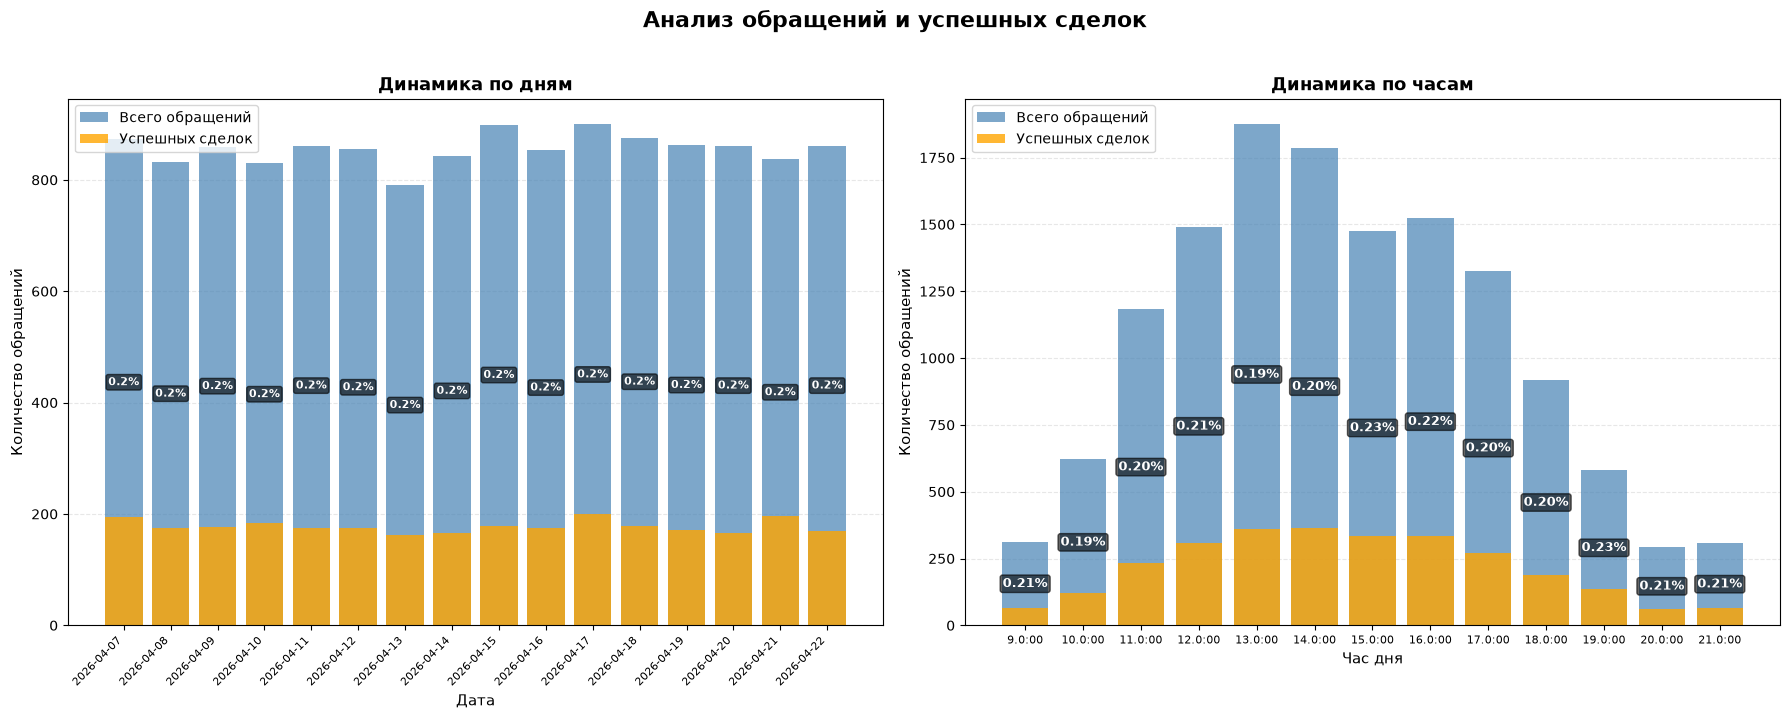

In [ ]:
target_from_day = train.groupby('assignment_date')['target'].agg(
    requests='size',
    deals_happened='sum',
    target_percentage='mean'
)

display(target_from_day)

target_from_hour = train.groupby('assignment_hour')['target'].agg(
    requests='size',
    deals_happened='sum',
    target_percentage='mean'
)

display(target_from_hour)

# Создаем фигуру с двумя сабплотами (1 строка, 2 колонки)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# ============ ГРАФИК 1: ПО ДНЯМ ============
# Столбцы для дней
bars1_day = ax1.bar(range(len(target_from_day)), 
                    target_from_day['requests'], 
                    label='Всего обращений', 
                    color='steelblue', 
                    alpha=0.7)

# Столбцы с успешными сделками
success_bars_day = ax1.bar(range(len(target_from_day)), 
                           target_from_day['deals_happened'], 
                           label='Успешных сделок', 
                           color='orange', 
                           alpha=0.8)

# Подписи процентов для дней
for i, row in enumerate(target_from_day.itertuples()):
    if row.requests > 0:
        ax1.text(i, row.requests / 2, 
                f"{row.target_percentage:.1f}%",
                ha='center', va='center', 
                fontsize=8, fontweight='bold', 
                color='white',
                bbox=dict(boxstyle="round,pad=0.2", facecolor='black', alpha=0.6))

# Настройка подписей для дней (показываем каждую N-ю дату)
step_day = max(1, len(target_from_day) // 15)
ax1.set_xticks(range(0, len(target_from_day), step_day))
ax1.set_xticklabels(target_from_day.index[::step_day], rotation=45, ha='right', fontsize=8)

# Оформление первого графика
ax1.set_xlabel('Дата', fontsize=11)
ax1.set_ylabel('Количество обращений', fontsize=11)
ax1.set_title('Динамика по дням', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.set_axisbelow(True)

# ============ ГРАФИК 2: ПО ЧАСАМ ============
# Столбцы для часов
bars1_hour = ax2.bar(range(len(target_from_hour)), 
                     target_from_hour['requests'], 
                     label='Всего обращений', 
                     color='steelblue', 
                     alpha=0.7)

# Столбцы с успешными сделками
success_bars_hour = ax2.bar(range(len(target_from_hour)), 
                            target_from_hour['deals_happened'], 
                            label='Успешных сделок', 
                            color='orange', 
                            alpha=0.8)

# Подписи процентов для часов
for i, row in enumerate(target_from_hour.itertuples()):
    if row.requests > 0:
        ax2.text(i, row.requests / 2, 
                f"{row.target_percentage:.2f}%",
                ha='center', va='center', 
                fontsize=9, fontweight='bold', 
                color='white',
                bbox=dict(boxstyle="round,pad=0.2", facecolor='black', alpha=0.6))

# Настройка подписей для часов
ax2.set_xticks(range(len(target_from_hour)))
ax2.set_xticklabels([f"{h}:00" for h in target_from_hour.index], fontsize=8)

# Оформление второго графика
ax2.set_xlabel('Час дня', fontsize=11)
ax2.set_ylabel('Количество обращений', fontsize=11)
ax2.set_title('Динамика по часам', fontsize=13, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.set_axisbelow(True)

# Общий заголовок
fig.suptitle('Анализ обращений и успешных сделок', fontsize=16, fontweight='bold', y=1.02)

# Автоматическая настройка отступов
plt.tight_layout()
plt.show()

### 2.2 Анти-утечка и логика признаков — почему берём именно такие фичи

**Обрабатываемые поля:** `events.event_ts` в сравнении с `assignment_ts`.

Главный барьер: для каждого обращения используем **только события с `event_ts < assignment_ts`**. В момент
скоринга будущее неизвестно, поэтому все агрегаты из `events.csv` считаются строго по прошлому — иначе метрика
будет завышена за счёт утечки. Проверка ниже показывает, что ~6% событий приходятся на будущее и отбрасываются.

Отсюда логика набора признаков (подробнее в разделе Feature engineering):

- **Оконные счётчики (1/3/7/14/30 дней).** Свежая активность сильнее связана с конверсией, чем старая;
  распределение давности доступных событий (график ниже) обосновывает выбор окон.
- **Recency (`days_since_last_*`).** Время с последнего события каждого типа.
- **Категориальные развёртки `ctx_seq` / `src_slot` / `event_typexctx_seq`.** По EDA target rate по этим полям
  разнится от ~0 до ~1 -> счётчики по категориям несут сигнал, которого нет в простом `nunique`.
- **Funnel и price-fit.** Глубина воронки намерения (view->favorite->chat->call) и соответствие цены обращения
  ценам просмотренных объявлений.
- **Sequence last-5.** Форма хвоста последовательности событий (нарастает ли интерес перед назначением).

Ни один признак не использует target и не завязан на конкретные `lead_id` — только поведение из прошлого.

,share
timing,
до назначения (используем),0.9367
после (отбрасываем),0.0633
нет события,0.0000


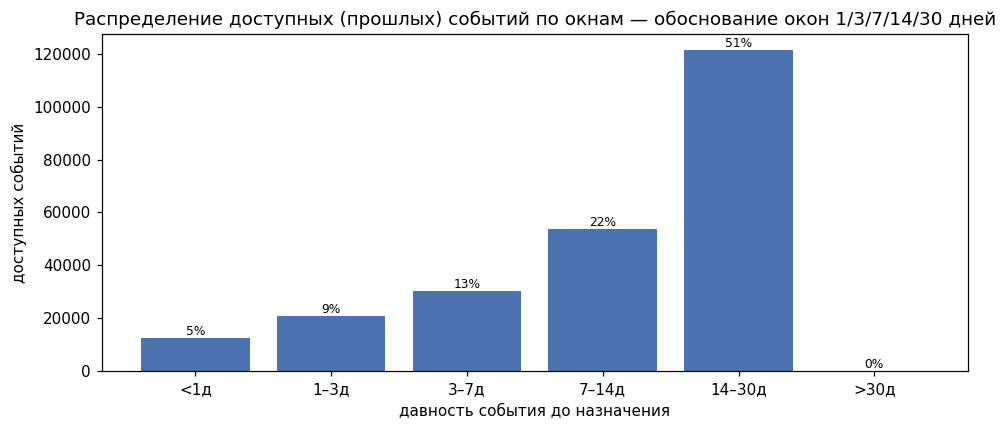

In [7]:
# Обрабатываемые поля: events.event_ts, assignment_ts (lead_id для джойна)
keys = pd.concat([train[["lead_id", "assignment_ts"]], test[["lead_id", "assignment_ts"]]], ignore_index=True)
ea = keys.merge(events[["lead_id", "event_ts"]], on="lead_id", how="left")
ea["delta_h"] = (ea["event_ts"] - ea["assignment_ts"]).dt.total_seconds() / 3600
ea["timing"] = np.where(
    ea["event_ts"].isna(), "нет события",
    np.where(ea["delta_h"] < 0, "до назначения (используем)", "после (отбрасываем)"),
)
display(ea["timing"].value_counts(normalize=True).round(4).to_frame("share"))

# доступные (прошлые) события раскладываем по окнам давности — это и есть окна наших признаков
past = ea[ea["delta_h"] < 0].copy()
past["age_days"] = -past["delta_h"] / 24
buckets = ["<1д", "1–3д", "3–7д", "7–14д", "14–30д", ">30д"]
counts = (pd.cut(past["age_days"], bins=[0, 1, 3, 7, 14, 30, np.inf], labels=buckets, right=True)
          .value_counts().reindex(buckets))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(buckets, counts.values, color="#4C72B0")
ax.bar_label(bars, labels=[f"{v / counts.sum() * 100:.0f}%" for v in counts.values], fontsize=8)
ax.set_ylabel("доступных событий"); ax.set_xlabel("давность события до назначения")
ax.set_title("Распределение доступных (прошлых) событий по окнам — обоснование окон 1/3/7/14/30 дней")
plt.tight_layout(); plt.show()

### 2.3 Сигнал в категориальных полях событий

**Обрабатываемые поля:** `events.ctx_seq`, `events.src_slot`, `events.event_type` (+ `target` для оценки сигнала).

Считаем долю позитивов по каждому значению `ctx_seq`, `src_slot` и по связке `event_type x ctx_seq`
(строго на прошлом, с минимальным порогом по числу лидов). Красная линия - средняя доля по train.
Сильный разброс - поле информативно и его стоит развернуть в признаки.

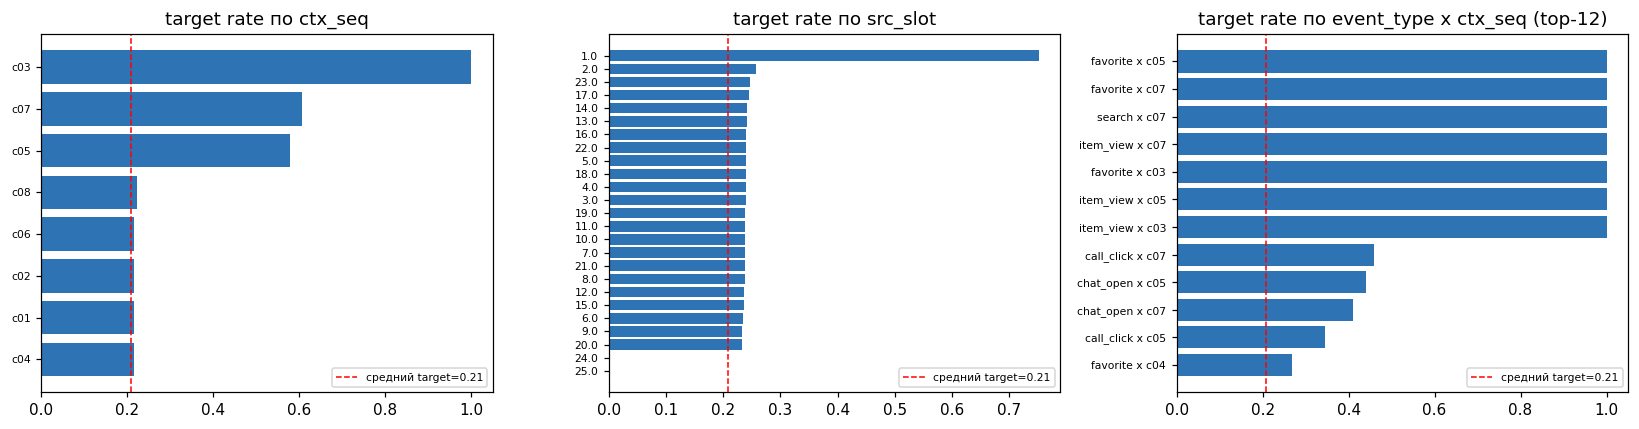

In [8]:
# Обрабатываемые поля: events.event_type, ctx_seq, src_slot; target (только для оценки сигнала на train)
safe = train[["lead_id", "assignment_ts", TARGET]].merge(events, on="lead_id", how="inner")
safe = safe[safe["event_ts"] < safe["assignment_ts"]].copy()  # только прошлое (анти-утечка)
safe["type_ctx"] = safe["event_type"].astype(str) + " x " + safe["ctx_seq"].astype(str)


def signal(col, min_leads=40):
    """Доля позитивов по значению категории (дедупликация по lead_id, порог по числу лидов)."""
    d = safe[["lead_id", TARGET, col]].drop_duplicates(["lead_id", col])
    t = d.groupby(col)[TARGET].agg(target_rate="mean", leads="size")
    return t[t["leads"] >= min_leads].sort_values("target_rate", ascending=False).round(4)


sig_ctx, sig_slot, sig_tc = signal("ctx_seq"), signal("src_slot"), signal("type_ctx")
base_rate = train[TARGET].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [(sig_ctx, "ctx_seq"), (sig_slot, "src_slot"), (sig_tc.head(12), "event_type x ctx_seq (top-12)")]
for ax, (s, title) in zip(axes, panels):
    ax.barh(range(len(s)), s["target_rate"], color="#2E74B5")
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index, fontsize=7)
    ax.axvline(base_rate, color="red", ls="--", lw=1, label=f"средний target={base_rate:.2f}")
    ax.invert_yaxis(); ax.set_title(f"target rate по {title}"); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## 3. Feature engineering

Пять блоков признаков. Каждый - отдельная функция; все события фильтруются `event_ts < assignment_ts`.

**Обработка пропусков в признаках**:
- **счётчики** (сколько событий/типов за окно) -> `0` при отсутствии событий;
- **recency** (время с последнего события) -> `NaN` как никогда (деревья работают с `NaN` нативно);
- **категориальные** признаки -> токен `"missing"` на этапе кодирования.

### 3.1 Константы блоков признаков

`EVENT_TYPES` — типы событий;

`HIGH_INTENT` — горячие действия (избранное/чат/звонок);

`INTENT_RANK` — порядок намерения для воронки (просмотр/поиск = 0 < избранное = 1 < чат = 2 < звонок = 3);

`*_WINDOWS` — временные окна агрегации в днях.

In [9]:
EVENT_TYPES = ["item_view", "search", "favorite", "chat_open", "call_click"]
HIGH_INTENT = ["favorite", "chat_open", "call_click"]                  # горячие действия
INTENT_RANK = {"item_view": 0, "search": 0, "favorite": 1, "chat_open": 2, "call_click": 3}
EVENT_WINDOWS = [1, 3, 7, 14, 30]      # окна для агрегатов событий
FUNNEL_WINDOWS = [7, 14, 30]           # окна для воронки намерения
CAT_WINDOWS = [7, 14, 30]              # окна для категориальных развёрток
LAST_N = 5                             # длина хвоста последовательности
EPS = 1e-6

### 3.2 Табличные конверсии и тренды — `add_combined_features`

**Обрабатываемые поля:** готовые оконные агрегаты из `train/test` (`item_views_*`, `item_favorites_*`,
`user_contacts_*`, `chat_opens_*`, `call_clicks_*`, `search_views_*`, `leadgen_prev_*`, `active_days_auto_*`,
`item_price_log`, `mileage_km_log`, `car_age_years`).

**Создаёт признаки:**
- *конверсии* по окнам 7/14/30д: `fav_per_view`, `contact_per_view`, `chat_per_contact`, `call_per_view`;
- *исторические доли* 30/90д: `prev_pos_rate` (доля положительных прошлых назначений), `prev_ans_rate`;
- *тренды свежесть/фон* (`*_trend` = активность за 3д против 30д) — растёт ли интерес;
- *нормировки* `*_per_day_90d`;
- *ценовые*: `price_minus_mileage`, `price_per_age`.

In [10]:
def add_combined_features(df: pd.DataFrame) -> pd.DataFrame:
    """Производные из готовых табличных агрегатов: конверсии, исторические доли, тренды, цена."""
    df = df.copy()
    # конверсии воронки по окнам
    for w in ["7d", "14d", "30d"]:
        df[f"fav_per_view_{w}"] = df[f"item_favorites_{w}"] / (df[f"item_views_{w}"] + 1)
        df[f"contact_per_view_{w}"] = df[f"user_contacts_{w}"] / (df[f"item_views_{w}"] + 1)
        df[f"chat_per_contact_{w}"] = df[f"chat_opens_{w}"] / (df[f"user_contacts_{w}"] + 1)
        df[f"call_per_view_{w}"] = df[f"call_clicks_{w}"] / (df[f"item_views_{w}"] + 1)
    # исторические доли по прошлым назначениям
    for w in ["30d", "90d"]:
        df[f"prev_pos_rate_{w}"] = df[f"leadgen_prev_positive_{w}"] / (df[f"leadgen_prev_assigned_{w}"] + 1)
        df[f"prev_ans_rate_{w}"] = df[f"leadgen_prev_answered_{w}"] / (df[f"leadgen_prev_assigned_{w}"] + 1)
    # тренд свежей активности против фоновой (3д против 30д)
    for stem in ["item_views", "user_contacts", "search_views", "call_clicks", "chat_opens"]:
        df[f"{stem}_trend"] = (df[f"{stem}_3d"] / 3) / (df[f"{stem}_30d"] / 30 + 0.1)
    for stem in ["item_views", "search_views", "active_days_auto"]:
        df[f"{stem}_per_day_90d"] = df[f"{stem}_90d"] / 90
    # ценовые производные
    df["price_minus_mileage"] = df["item_price_log"] - df["mileage_km_log"]
    df["price_per_age"] = df["item_price_log"] / (df["car_age_years"] + 1)
    return df

### 3.3 Агрегаты событий по окнам - `build_event_features`

**Обрабатываемые поля:** `events` (`event_type`, `event_ts`, `src_slot`, `ctx_seq`, `item_price_log`),
только `event_ts < assignment_ts`.

**Создаёт признаки:**
- *счётчики по типам* в окнах 1/3/7/14/30д (`ev_<type>_<w>d`), суммарные `ev_total_<w>d`,
  горячие `ev_hi_<w>d`, разнообразие `ev_uniq_slot/ctx_<w>d`, средняя цена `ev_price_mean_<w>d`;
- *recency*: `ev_days_since_last/first`, `ev_span_days`, время с последнего события каждого типа и горячего;
- *momentum*: отношение активности 3д к 14д (общей и горячей), доля горячих за 14д;
- *регулярность*: средний/макс/std интервал между событиями, число активных дней за 30д;
- *контекст*: доля ночных/выходных событий, последний тип события и последний горячий тип.

In [11]:
def build_event_features(base: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Агрегаты поведения из events.csv по временным окнам (строго на прошлом)."""
    ev = events.merge(base[["lead_id", "assignment_ts"]], on="lead_id", how="inner")
    ev = ev[ev["event_ts"] < ev["assignment_ts"]].copy()  # анти-утечка
    ev["age_days"] = (ev["assignment_ts"] - ev["event_ts"]).dt.total_seconds() / 86400.0
    ev["is_hi"] = ev["event_type"].isin(HIGH_INTENT)
    ev["hour"] = ev["event_ts"].dt.hour
    ev["is_night"] = ev["hour"].isin(range(0, 7))
    ev["is_weekend"] = ev["event_ts"].dt.weekday >= 5
    ev = ev.sort_values(["lead_id", "event_ts"])
    idx = pd.Index(base["lead_id"].unique(), name="lead_id")
    parts = []

    # --- счётчики по типам событий в каждом окне ---
    for w in EVENT_WINDOWS:
        win = ev[ev["age_days"] <= w]
        g = win.groupby("lead_id")
        counts = (win.groupby(["lead_id", "event_type"]).size().unstack(fill_value=0)
                  .reindex(columns=EVENT_TYPES, fill_value=0).add_prefix("ev_").add_suffix(f"_{w}d"))
        agg = pd.DataFrame({
            f"ev_total_{w}d": g.size(), f"ev_hi_{w}d": g["is_hi"].sum(),
            f"ev_uniq_slot_{w}d": g["src_slot"].nunique(), f"ev_uniq_ctx_{w}d": g["ctx_seq"].nunique(),
            f"ev_price_mean_{w}d": g["item_price_log"].mean(),
        })
        parts.append(counts.reindex(idx, fill_value=0))
        parts.append(agg.reindex(idx).fillna({c: 0 for c in agg.columns if "price" not in c}))

    g_all = ev.groupby("lead_id")

    # --- recency: время с последнего/первого события ---
    recency = pd.DataFrame({"ev_days_since_last": g_all["age_days"].min()})
    recency["ev_days_since_first"] = g_all["age_days"].max()
    recency["ev_span_days"] = recency["ev_days_since_first"] - recency["ev_days_since_last"]
    for t in EVENT_TYPES:
        recency[f"ev_days_since_last_{t}"] = ev[ev["event_type"] == t].groupby("lead_id")["age_days"].min()
    recency["ev_days_since_last_hi"] = ev[ev["is_hi"]].groupby("lead_id")["age_days"].min()
    parts.append(recency.reindex(idx))

    # --- momentum: свежая активность против фоновой ---
    momentum = pd.DataFrame(index=idx)
    t3 = ev[ev["age_days"] <= 3].groupby("lead_id").size().reindex(idx, fill_value=0)
    t14 = ev[ev["age_days"] <= 14].groupby("lead_id").size().reindex(idx, fill_value=0)
    momentum["ev_momentum_3_14"] = t3 / (t14 + 1)
    h3 = ev[(ev["age_days"] <= 3) & ev["is_hi"]].groupby("lead_id").size().reindex(idx, fill_value=0)
    h14 = ev[(ev["age_days"] <= 14) & ev["is_hi"]].groupby("lead_id").size().reindex(idx, fill_value=0)
    momentum["ev_hi_momentum_3_14"] = h3 / (h14 + 1)
    momentum["ev_hi_share_14d"] = h14 / (t14 + 1)
    parts.append(momentum)

    # --- регулярность: интервалы между событиями и активные дни ---
    ev["gap_d"] = ev.groupby("lead_id")["event_ts"].diff().dt.total_seconds() / 86400.0
    regularity = pd.DataFrame({"ev_gap_mean_d": g_all["gap_d"].mean(), "ev_gap_std_d": g_all["gap_d"].std(),
                               "ev_gap_max_d": g_all["gap_d"].max()})
    ev30 = ev[ev["age_days"] <= 30]
    regularity["ev_active_days_30d"] = ev30.groupby("lead_id")["event_ts"].apply(lambda s: s.dt.date.nunique())
    parts.append(regularity.reindex(idx).fillna({"ev_active_days_30d": 0}))

    # --- контекст: цена, ночь/выходные, последний тип события ---
    misc = pd.DataFrame({"ev_price_std_30d": ev30.groupby("lead_id")["item_price_log"].std(),
                         "ev_night_share_14d": ev[ev["age_days"] <= 14].groupby("lead_id")["is_night"].mean(),
                         "ev_weekend_share_14d": ev[ev["age_days"] <= 14].groupby("lead_id")["is_weekend"].mean()})
    parts.append(misc.reindex(idx))
    last_type = g_all["event_type"].last().rename("ev_last_type")
    last_hi = ev[ev["is_hi"]].groupby("lead_id")["event_type"].last().rename("ev_last_hi_type")
    parts.append(pd.concat([last_type, last_hi], axis=1).reindex(idx))

    return pd.concat(parts, axis=1).reset_index()

### 3.4 Соответствие цены и воронка намерения — `build_tier1_event_features`

**Обрабатываемые поля:** `events.item_price_log`, `event_type`, `event_ts`; цена обращения `item_price_log`
из `train/test`.

**Создаёт признаки:**
- *price-fit* (насколько цена обращения похожа на цены просмотренных объявлений): `pf_price_diff/absdiff/z`,
  `pf_price_position` (позиция в диапазоне цен), `pf_price_cv`, `pf_share_cheaper`, `pf_last_price_diff`;
- *воронка намерения* по рангам (просмотр<избранное<чат<звонок) в окнах 7/14/30д: максимальный достигнутый
  уровень `fn_maxrank`, число уровней, флаги достижения `fn_reached_favorite/chat/call`, доля «глубоких»
  действий, тренд ранга `fn_rank_trend`, флаг «когда-либо звонок».

In [12]:
def build_tier1_event_features(base: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Соответствие цены обращения истории просмотров + глубина воронки намерения."""
    ev = events.merge(
        base[["lead_id", "assignment_ts", "item_price_log"]].rename(columns={"item_price_log": "assign_price"}),
        on="lead_id", how="inner",
    )
    ev = ev[ev["event_ts"] < ev["assignment_ts"]].copy()
    ev["age_days"] = (ev["assignment_ts"] - ev["event_ts"]).dt.total_seconds() / 86400.0
    ev["rank"] = ev["event_type"].map(INTENT_RANK)
    ev = ev.sort_values(["lead_id", "event_ts"])
    idx = pd.Index(base["lead_id"].unique(), name="lead_id")
    g = ev.groupby("lead_id")
    parts = []

    # --- price-fit: цена обращения относительно цен просмотренных объявлений ---
    pf = pd.DataFrame({"pf_ev_price_mean": g["item_price_log"].mean(), "pf_ev_price_std": g["item_price_log"].std(),
                       "pf_ev_price_min": g["item_price_log"].min(), "pf_ev_price_max": g["item_price_log"].max(),
                       "pf_ev_price_median": g["item_price_log"].median()})
    pf["assign_price"] = base.set_index("lead_id")["item_price_log"].reindex(pf.index)
    pf["pf_price_diff"] = pf["assign_price"] - pf["pf_ev_price_mean"]
    pf["pf_price_absdiff"] = pf["pf_price_diff"].abs()
    pf["pf_price_z"] = pf["pf_price_diff"] / (pf["pf_ev_price_std"] + EPS)
    pf["pf_price_range"] = pf["pf_ev_price_max"] - pf["pf_ev_price_min"]
    pf["pf_price_position"] = (pf["assign_price"] - pf["pf_ev_price_min"]) / (pf["pf_price_range"] + EPS)
    pf["pf_price_cv"] = pf["pf_ev_price_std"] / (pf["pf_ev_price_mean"].abs() + EPS)
    ev["_cheaper"] = ev["item_price_log"] < ev["assign_price"]
    pf["pf_share_cheaper"] = g["_cheaper"].mean()
    pf["pf_last_price_diff"] = pf["assign_price"] - ev.groupby("lead_id")["item_price_log"].last()
    pf = pf.drop(columns=["assign_price"])
    parts.append(pf.reindex(idx))

    # --- воронка намерения: как глубоко дошёл пользователь ---
    fn = pd.DataFrame(index=idx)
    for w in FUNNEL_WINDOWS:
        win = ev[ev["age_days"] <= w]
        gw = win.groupby("lead_id")
        fn[f"fn_maxrank_{w}d"] = gw["rank"].max().reindex(idx)
        deep = win[win["rank"] >= 1]
        fn[f"fn_levels_{w}d"] = deep.groupby("lead_id")["rank"].nunique().reindex(idx).fillna(0)
        fn[f"fn_reached_favorite_{w}d"] = (gw["rank"].max().reindex(idx) >= 1).astype("float")
        fn[f"fn_reached_chat_{w}d"] = (gw["rank"].max().reindex(idx) >= 2).astype("float")
        fn[f"fn_reached_call_{w}d"] = (gw["rank"].max().reindex(idx) >= 3).astype("float")
        fn[f"fn_deep_share_{w}d"] = (win[win["rank"] >= 2].groupby("lead_id").size().reindex(idx, fill_value=0)
                                     / (gw.size().reindex(idx, fill_value=0) + 1))
    fn["fn_rank_trend"] = (ev[ev["age_days"] <= 3].groupby("lead_id")["rank"].mean().reindex(idx)
                           - ev[ev["age_days"] > 3].groupby("lead_id")["rank"].mean().reindex(idx))
    fn["fn_ever_call"] = (g["rank"].max().reindex(idx) >= 3).astype("float")
    parts.append(fn)
    return pd.concat(parts, axis=1).reset_index()

### 3.5 Форма последних N событий — `build_sequence_features`

**Обрабатываемые поля:** последние `LAST_N=5` событий из `events` (`event_type`, `event_ts`, `item_price_log`).

**Создаёт признаки** (форма хвоста перед назначением): число горячих `seq_hi_cnt`, средний/макс ранг
намерения, число уникальных типов, наклон ранга по позиции `seq_rank_slope` (нарастает ли интерес),
число переключений типов `seq_switches`, длительность и темп хвоста, последняя биграмма переходов
`seq_last_bigram` (категориальный), разброс цены в хвосте.

In [13]:
def build_sequence_features(base: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Форма последних LAST_N событий: динамика намерения перед назначением."""
    ev = events.merge(base[["lead_id", "assignment_ts"]], on="lead_id", how="inner")
    ev = ev[ev["event_ts"] < ev["assignment_ts"]].copy()
    ev["rank_intent"] = ev["event_type"].map(INTENT_RANK)
    ev["is_hi"] = ev["event_type"].isin(HIGH_INTENT)
    ev = ev.sort_values(["lead_id", "event_ts"])
    idx = pd.Index(base["lead_id"].unique(), name="lead_id")

    tail = ev.groupby("lead_id").tail(LAST_N).copy()
    tail["pos"] = tail.groupby("lead_id").cumcount()
    g = tail.groupby("lead_id")

    out = pd.DataFrame(index=idx)
    out[f"seq_hi_cnt_last{LAST_N}"] = g["is_hi"].sum().reindex(idx)
    out[f"seq_rank_mean_last{LAST_N}"] = g["rank_intent"].mean().reindex(idx)
    out[f"seq_rank_max_last{LAST_N}"] = g["rank_intent"].max().reindex(idx)
    out[f"seq_uniq_types_last{LAST_N}"] = g["event_type"].nunique().reindex(idx)

    def _slope(gr):
        # наклон ранга намерения по позиции: >0 — интерес нарастает к моменту назначения
        if len(gr) < 2 or gr["rank_intent"].nunique() == 1:
            return 0.0
        return float(np.polyfit(gr["pos"], gr["rank_intent"], 1)[0])

    out[f"seq_rank_slope_last{LAST_N}"] = g[["pos", "rank_intent"]].apply(_slope).reindex(idx)
    out[f"seq_switches_last{LAST_N}"] = g["event_type"].apply(lambda s: (s != s.shift()).sum() - 1).reindex(idx)
    span = (g["event_ts"].max() - g["event_ts"].min()).dt.total_seconds() / 86400.0
    out[f"seq_span_days_last{LAST_N}"] = span.reindex(idx)
    out[f"seq_events_per_day_last{LAST_N}"] = g.size().reindex(idx) / (span.reindex(idx) + 0.5)
    out["seq_last_bigram"] = (g["event_type"].apply(lambda s: "|".join(s.iloc[-2:]) if len(s) >= 2 else "short")
                              .reindex(idx).fillna("none"))
    out[f"seq_price_std_last{LAST_N}"] = g["item_price_log"].std().reindex(idx)
    return out.reset_index()

### 3.6 Развёртка категориальных полей событий — `build_category_features` (+ циклическое время)

**Обрабатываемые поля:** `events.ctx_seq`, `events.src_slot`, `events.event_type`; `assignment_hour`,
`assignment_weekday` (для циклического кодирования). Это блок, давший основной прирост.

**Создаёт признаки:**
- *оконные счётчики по категориям* (`all/7/14/30д`): `ctx_*` (по `ctx_seq`), `slot_*` (по `src_slot`),
  `tc_*` (по связке `event_type x ctx_seq`);
- *recency по каждой категории*: `ctxrec__*`, `slotrec__*` (время с последнего события в этой категории);
- *последние категории*: `cat_last_ctx`, `cat_last_slot`; множество встреченных `ctx` — `cat_ctx_set`.
  Множество `src_slot` **не берём** — оно почти уникально на строку (ID-подобно, риск переобучения).
- *циклическое время*: `hour_sin/cos`, `wd_sin/cos` (час 23 и 0 — рядом).

In [ ]:
def _slot_token(s):
    """src_slot (число) -> строковый токен 'sN' для использования как категории."""
    return "s" + pd.to_numeric(s, errors="coerce").astype("Int64").astype(str)


def build_category_features(base: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Развёртка ctx_seq / src_slot / (event_type x ctx_seq) в оконные счётчики, recency и last-категории."""
    ev = events.merge(base[["lead_id", "assignment_ts"]], on="lead_id", how="inner")
    ev = ev[ev["event_ts"] < ev["assignment_ts"]].copy()
    ev["age_days"] = (ev["assignment_ts"] - ev["event_ts"]).dt.total_seconds() / 86400.0
    ev["ctx"] = ev["ctx_seq"].astype(str)
    ev["slot"] = _slot_token(ev["src_slot"])
    ev["typectx"] = ev["event_type"].astype(str) + "__" + ev["ctx"]
    ev = ev.sort_values(["lead_id", "event_ts"])
    idx = pd.Index(base["lead_id"].unique(), name="lead_id")
    parts = []

    def windowed_counts(col, prefix, windows):
        # полное окно + по каждому окну: счётчики каждой категории
        parts.append(ev.groupby(["lead_id", col]).size().unstack(fill_value=0)
                     .add_prefix(f"{prefix}_all__").reindex(idx, fill_value=0))
        for w in windows:
            win = ev[ev["age_days"] <= w]
            parts.append(win.groupby(["lead_id", col]).size().unstack(fill_value=0)
                         .add_prefix(f"{prefix}_{w}d__").reindex(idx, fill_value=0))

    windowed_counts("ctx", "ctx", CAT_WINDOWS)
    windowed_counts("slot", "slot", CAT_WINDOWS)
    windowed_counts("typectx", "tc", [14])

    # recency по каждой категории
    for col, prefix in [("ctx", "ctxrec"), ("slot", "slotrec")]:
        parts.append(ev.groupby(["lead_id", col])["age_days"].min().unstack().add_prefix(f"{prefix}__").reindex(idx))

    # последние категории и множество ctx
    g = ev.groupby("lead_id")
    tail = pd.DataFrame(index=idx)
    tail["cat_last_ctx"] = g["ctx"].last().reindex(idx)
    tail["cat_last_slot"] = g["slot"].last().reindex(idx)
    tail["cat_ctx_set"] = g["ctx"].apply(lambda s: "|".join(sorted(set(s)))).reindex(idx)
    parts.append(tail)

    return pd.concat(parts, axis=1).reset_index()


def add_cyclical(df: pd.DataFrame) -> pd.DataFrame:
    """Циклическое кодирование времени назначения (час, день недели)."""
    df = df.copy()
    h = pd.to_numeric(df["assignment_hour"], errors="coerce")
    wd = pd.to_numeric(df["assignment_weekday"], errors="coerce")
    df["hour_sin"] = np.sin(2 * np.pi * h / 24)
    df["hour_cos"] = np.cos(2 * np.pi * h / 24)
    df["wd_sin"] = np.sin(2 * np.pi * wd / 7)
    df["wd_cos"] = np.cos(2 * np.pi * wd / 7)
    return df

### 3.7 Сборка матрицы признаков и обработка пропусков

Применяем все блоки к `train` и `test` одинаково, склеиваем по `lead_id`. Счётчики нового
категориального блока заполняем нулями (нет событий = 0), recency оставляем как `NaN`.

In [15]:
# табличные производные + агрегаты событий
train_fe = add_combined_features(train).merge(build_event_features(train, events), on="lead_id", how="left")
test_fe = add_combined_features(test).merge(build_event_features(test, events), on="lead_id", how="left")
# price-fit + воронка
train_fe = train_fe.merge(build_tier1_event_features(train, events), on="lead_id", how="left")
test_fe = test_fe.merge(build_tier1_event_features(test, events), on="lead_id", how="left")
# sequence last-N
seq_train = build_sequence_features(train, events)
train_fe = train_fe.merge(seq_train, on="lead_id", how="left")
test_fe = test_fe.merge(build_sequence_features(test, events), on="lead_id", how="left")
SEQ_FEATS = [c for c in seq_train.columns if c != "lead_id"]
# категориальные развёртки + циклическое время
cat_train = build_category_features(train, events)
train_fe = add_cyclical(train_fe).merge(cat_train, on="lead_id", how="left")
test_fe = add_cyclical(test_fe).merge(build_category_features(test, events), on="lead_id", how="left")
NEW_CAT_FEATS = [c for c in cat_train.columns if c != "lead_id"] + ["hour_sin", "hour_cos", "wd_sin", "wd_cos"]

# пропуски: счётчики -> 0, recency (ctxrec/slotrec) -> оставляем NaN
count_cols = [c for c in NEW_CAT_FEATS if ("__" in c) and not c.startswith(("ctxrec", "slotrec"))]
train_fe[count_cols] = train_fe[count_cols].fillna(0)
test_fe[count_cols] = test_fe[count_cols].fillna(0)

print("итоговая матрица:", train_fe.shape, "| test:", test_fe.shape,
      "| sequence:", len(SEQ_FEATS), "| новый кат.блок:", len(NEW_CAT_FEATS))

итоговая матрица: (13694, 511) | test: (4306, 510) | sequence: 10 | новый кат.блок: 252


## 4. Кодирование категорий, корреляционный отсев, гиперпараметры и SHAP

- **Категории.** Строим единый словарь по `train+test`, пропуски -> токен `"missing"`. Так модель одинаково
  видит категории в обучении и на тесте, а редкие/новые значения не ломают пайплайн.
- **Временной сплит 80/20** по датам — для отсева и SHAP (никакого случайного перемешивания).
- **Корреляционный отсев** `|r|>0.95`: из пары дубликатов оставляем сильнее связанный с target.

In [16]:
# единый словарь категорий по train+test; пропуски -> "missing"
all_cols = [c for c in train_fe.columns if c not in NON_FEATURE_COLUMNS and c in test_fe.columns]
cat_cols = [c for c in all_cols if not pd.api.types.is_numeric_dtype(train_fe[c])]
for c in cat_cols:
    cats = sorted(pd.concat([train_fe[c], test_fe[c]]).astype("object").fillna("missing").unique())
    train_fe[c] = pd.Categorical(train_fe[c].astype("object").fillna("missing"), categories=cats)
    test_fe[c] = pd.Categorical(test_fe[c].astype("object").fillna("missing"), categories=cats)
print(f"всего признаков: {len(all_cols)} | категориальных: {len(cat_cols)}")

# временной сплит 80/20 для отсева и SHAP
dates_all = train_fe["assignment_date"].dt.date
ordered_dates = sorted(dates_all.unique())
cut = ordered_dates[int(len(ordered_dates) * 0.8)]
train_part, valid_part = train_fe[dates_all < cut], train_fe[dates_all >= cut]

# корреляционный отсев дубликатов (sequence в отсеве не участвует, добавится в пул отдельно)
candidate_feats = [c for c in all_cols if c not in SEQ_FEATS]
num_feats = [c for c in candidate_feats if pd.api.types.is_numeric_dtype(train_fe[c])]
corr = train_part[num_feats].corr().abs()
tcorr = train_part[num_feats].corrwith(train_part[TARGET]).abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = set()
for a, b in upper.stack().loc[lambda s: s > CORR_THRESHOLD].index:
    if a in to_drop or b in to_drop:
        continue
    to_drop.add(a if tcorr.get(a, 0) < tcorr.get(b, 0) else b)
POOL = [c for c in candidate_feats if c not in to_drop] + SEQ_FEATS
print(f"|corr|>{CORR_THRESHOLD}: удалили {len(to_drop)} -> пул для отбора: {len(POOL)} признаков (вкл. sequence)")

всего признаков: 506 | категориальных: 13
|corr|>0.95: удалили 83 -> пул для отбора: 423 признаков (вкл. sequence)


### 4.1 Гиперпараметры моделей (подобраны оффлайн через Optuna отдельным скриптом в ходе экспериментов)

Гиперпараметры CatBoost и XGBoost подобраны заранее отдельным Optuna-исследованием (оптимизация
Daily AP на временной кросс-валидации) и **зашиты прямо в код (я решил, что так сэкономлю время на проверке)** - чтобы решение воспроизводилось без
внешних файлов и без повторного запуска дорогого перебора. (На крайний случай, надеюсь, можно условиться, что параметры подобраны эмпирически) Схема, которой они получены (для справки, в
ноутбуке не запускается):

```python
import optuna
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 5e-3, 0.1, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 30),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-2, 10, log=True),
    }
    return cv_daily_ap(params)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)
```

In [17]:
# --- гиперпараметры XGBoost (с Optuna которую запускал) ---
xgb_params = dict(
    n_estimators=3000,
    learning_rate=0.016466384487172216,
    max_depth=4,
    min_child_weight=6,
    subsample=0.8914398190691173,
    colsample_bytree=0.7419859438282314,
    reg_lambda=0.7250809137042682,
    reg_alpha=0.73317466412198,
    tree_method="hist",
    enable_categorical=True,       # нативная работа с категориями и NaN
    eval_metric="aucpr",
    early_stopping_rounds=200,
    n_jobs=-1,
)

# --- гиперпараметры CatBoost (с Optuna которую запускал) ---
cb_params = dict(
    loss_function="Logloss",
    eval_metric="PRAUC",
    iterations=3000,
    learning_rate=0.022288917231613994,
    depth=4,
    l2_leaf_reg=3.0627005018776474,
    min_data_in_leaf=40,
    subsample=0.982641454148908,
    rsm=0.6550285753347196,
    bootstrap_type="Bernoulli",
    od_type="Iter", od_wait=200,
    verbose=False, allow_writing_files=False,
)
print("гиперпараметры от Optuna зашиты в код")

гиперпараметры от Optuna зашиты в код


### 4.2 Важность признаков через библиотеку SHAP

Обучаем XGBoost на пуле признаков и считаем **значения SHAP (TreeSHAP)** библиотекой `shap`.
Beeswarm показывает направление и величину вклада каждого признака, bar — среднюю |SHAP|.
Из средней |SHAP| получаем рейтинг признаков, по которому дальше идёт отбор.

Beeswarm — вклад топ-20 признаков (цвет = значение признака):


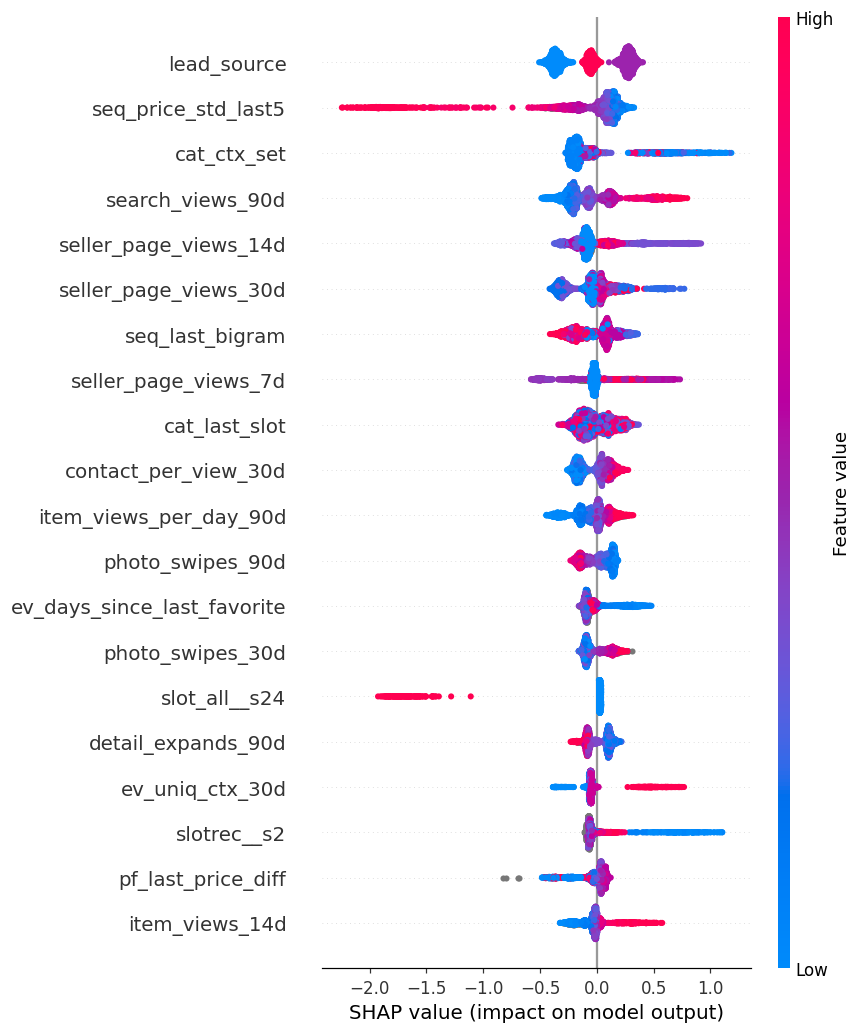

Bar — средняя |SHAP| топ-20:


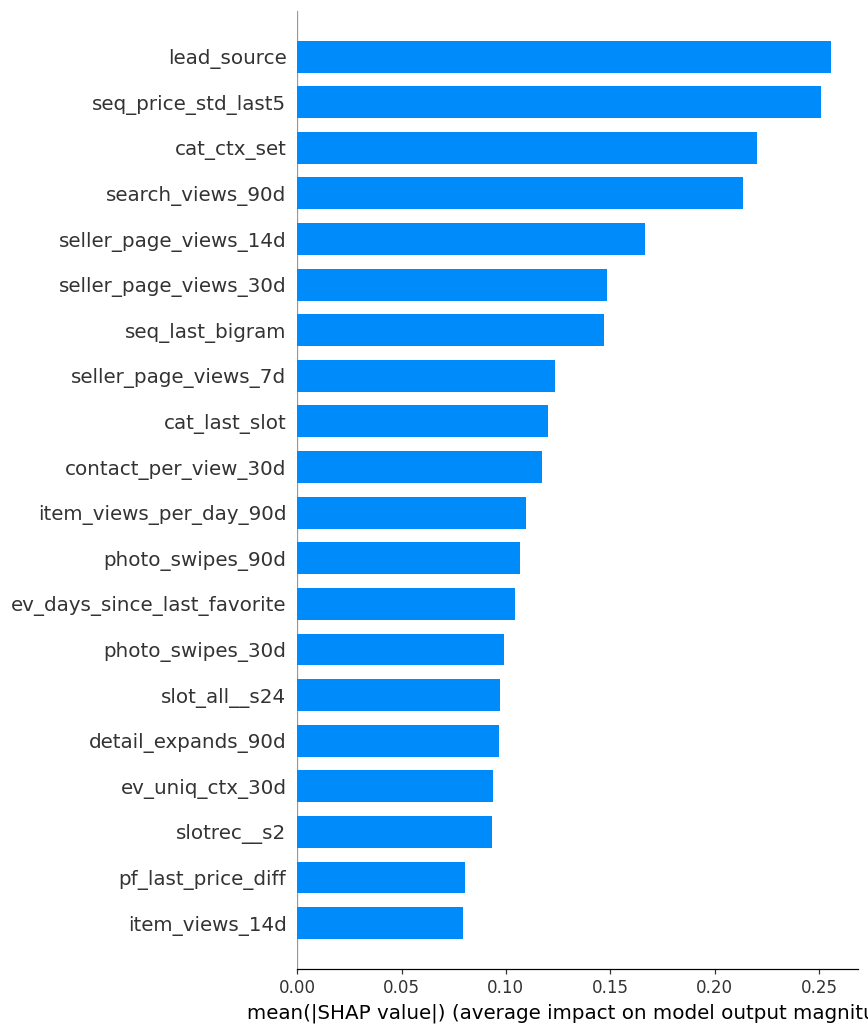

\nновых категориальных признаков в топ-20 SHAP: 4 -> ['cat_ctx_set', 'cat_last_slot', 'slot_all__s24', 'slotrec__s2']


,feature,shap
0,lead_source,0.255909
1,seq_price_std_last5,0.250862
2,cat_ctx_set,0.220111
3,search_views_90d,0.213819
4,seller_page_views_14d,0.166694
5,seller_page_views_30d,0.148331
6,seq_last_bigram,0.147022
7,seller_page_views_7d,0.123333
8,cat_last_slot,0.120178
9,contact_per_view_30d,0.117163


In [18]:
shap_xgb = xgb.XGBClassifier(**xgb_params, random_state=RANDOM_STATE)
shap_xgb.fit(train_part[POOL], train_part[TARGET],
             eval_set=[(valid_part[POOL], valid_part[TARGET])], verbose=False)

explainer = shap.TreeExplainer(shap_xgb)
Xv = valid_part[POOL]
Xv_num = Xv.copy()
for c in Xv_num.columns:
    if str(Xv_num[c].dtype) == "category":
        Xv_num[c] = Xv_num[c].cat.codes
sv = explainer.shap_values(Xv, check_additivity=False)

print("Beeswarm — вклад топ-20 признаков (цвет = значение признака):")
shap.summary_plot(sv, Xv_num, feature_names=POOL, max_display=20, show=False)
plt.tight_layout(); plt.show()

print("Bar — средняя |SHAP| топ-20:")
shap.summary_plot(sv, Xv_num, feature_names=POOL, plot_type="bar", max_display=20, show=False)
plt.tight_layout(); plt.show()

# рейтинг признаков по средней |SHAP|
shap_imp = np.abs(sv).mean(0)
ranking = pd.DataFrame({"feature": POOL, "shap": shap_imp}).sort_values("shap", ascending=False).reset_index(drop=True)
POOL_RANKED = ranking["feature"].tolist()
new_in_top20 = [f for f in POOL_RANKED[:20] if f in NEW_CAT_FEATS]
print(f"\\nновых категориальных признаков в топ-20 SHAP: {len(new_in_top20)} -> {new_in_top20}")
display(ranking.head(15))

**Как читать графики.** Beeswarm: каждая точка - обращение; по горизонтали - вклад признака в скор
(вправо -> повышает вероятность конверсии), цвет - величина самого признака. Bar - средняя |SHAP|
(сила влияния в среднем). Новые категориальные признаки (`cat_ctx_set`, счётчики `ctx/slot`, `type_ctx`)
попадают в топ - это подтверждает пользу нового блока.

## 5. Отбор признаков: forward-selection по SHAP на expanding-window CV

Добавляем признаки по убыванию SHAP-важности (лучший 1 -> топ-2 -> ...) и на каждом размере меряем Daily AP
быстрым XGBoost на expanding-window. Число признаков `N*` с максимумом Daily AP - финальный набор.
Быстрый скорер (меньше деревьев) используется только для отбора; финальные модели - полные.

exp[2026-04-14..2026-04-16]: train=5901 valid=2595
exp[2026-04-17..2026-04-19]: train=8496 valid=2639
exp[2026-04-20..2026-04-22]: train=11135 valid=2559
Лучшее N* = 65 (forward DAP быстрого скорера = 0.71931)


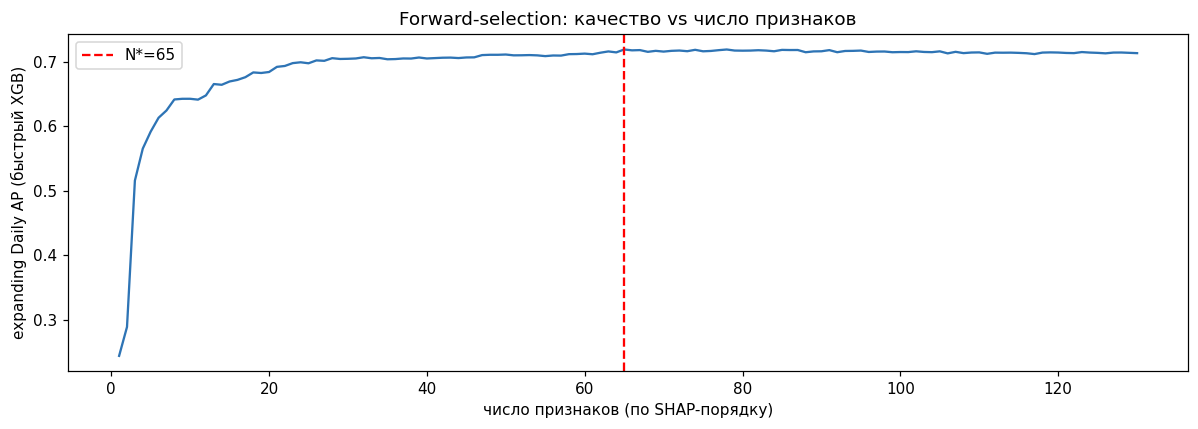

In [19]:
def make_expanding_folds(frame, starts=(7, 10, 13), horizon=3):
    """Expanding-window фолды: обучение на прошлом, валидация на следующих `horizon` днях."""
    d = frame["assignment_date"].dt.date
    dates = sorted(d.unique())
    folds = []
    for s in starts:
        vd = dates[s:s + horizon]
        if vd:
            folds.append((f"exp[{vd[0]}..{vd[-1]}]", (d < vd[0]).values, d.isin(vd).values))
    return folds


EXP_FOLDS = make_expanding_folds(train_fe)
for name, tr, va in EXP_FOLDS:
    print(f"{name}: train={tr.sum()} valid={va.sum()}")

# быстрый скорер для отбора: меньше деревьев -> быстрее, порядок важностей сохраняется
xgb_light = {**xgb_params, "n_estimators": 800, "early_stopping_rounds": 50}


def dap_light(feats):
    """Средний Daily AP быстрого XGBoost на expanding-window по набору признаков `feats`."""
    scores = []
    for _, tr_mask, va_mask in EXP_FOLDS:
        a, b = train_fe.loc[tr_mask], train_fe.loc[va_mask]
        m = xgb.XGBClassifier(**xgb_light, random_state=RANDOM_STATE)
        m.fit(a[feats], a[TARGET], eval_set=[(b[feats], b[TARGET])], verbose=False)
        scores.append(daily_average_precision(b["assignment_date"].dt.date, b[TARGET], m.predict_proba(b[feats])[:, 1]))
    return float(np.mean(scores))


MAX_FWD = min(130, len(POOL_RANKED))
fwd = [(k, dap_light(POOL_RANKED[:k])) for k in range(1, MAX_FWD + 1)]
fwd_df = pd.DataFrame(fwd, columns=["N", "DAP"])
BEST_N, BEST_DAP = max(fwd, key=lambda t: t[1])
FINAL_FEATS = POOL_RANKED[:BEST_N]
print(f"Лучшее N* = {BEST_N} (forward DAP быстрого скорера = {BEST_DAP:.5f})")

plt.figure(figsize=(11, 4))
plt.plot(fwd_df["N"], fwd_df["DAP"], color="#2E74B5")
plt.axvline(BEST_N, color="red", ls="--", label=f"N*={BEST_N}")
plt.xlabel("число признаков (по SHAP-порядку)"); plt.ylabel("expanding Daily AP (быстрый XGB)")
plt.title("Forward-selection: качество vs число признаков"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Финальный ансамбль CatBoost + XGBoost -> `submission.csv`

Обе модели обучаем на отобранных признаках и оцениваем на expanding-window. Предсказания смешиваем по
**внутридневным рангам**, вес подбираем по CV. Затем дообучаем на всём train (число итераций берём из
последнего expanding-фолда x1.15) с усреднением по 3 сидам и пишем `submission.csv`.

In [20]:
# категориальные признаки среди отобранных (для CatBoost и enable_categorical XGBoost)
cat_feats = [c for c in FINAL_FEATS if not pd.api.types.is_numeric_dtype(train_fe[c])]
print(f"Финальный набор: {len(FINAL_FEATS)} признаков | категориальных: {cat_feats}")


def fit_fold(tr, va):
    """Обучение обеих моделей на одном фолде. Возвращает усреднённые по сидам предсказания и лучшую итерацию."""
    Xtr, Xva = tr[FINAL_FEATS].copy(), va[FINAL_FEATS].copy()
    for c in cat_feats:
        Xtr[c] = Xtr[c].astype(str)
        Xva[c] = Xva[c].astype(str)
    cb_pred, xgb_pred, cb_it, xgb_it = [], [], [], []
    for s in CV_SEEDS:
        m = cb.CatBoostClassifier(**cb_params, random_seed=s)
        m.fit(Xtr, tr[TARGET], eval_set=(Xva, va[TARGET]), cat_features=cat_feats, use_best_model=True)
        cb_pred.append(m.predict_proba(Xva)[:, 1]); cb_it.append(m.get_best_iteration())
    for s in CV_SEEDS:
        m = xgb.XGBClassifier(**xgb_params, random_state=s)
        m.fit(tr[FINAL_FEATS], tr[TARGET], eval_set=[(va[FINAL_FEATS], va[TARGET])], verbose=False)
        xgb_pred.append(m.predict_proba(va[FINAL_FEATS])[:, 1]); xgb_it.append(m.best_iteration)
    return np.mean(cb_pred, 0), np.mean(xgb_pred, 0), int(np.mean(cb_it)), int(np.mean(xgb_it))


fold_res, last_it = [], None
for name, tr_mask, va_mask in EXP_FOLDS:
    tr, va = train_fe.loc[tr_mask], train_fe.loc[va_mask]
    d = va["assignment_date"].dt.date
    cb_p, xgb_p, cb_it, xgb_it = fit_fold(tr, va)
    fold_res.append({"d": d, "y": va[TARGET].values,
                     "cb": daily_rank(d, cb_p), "xgb": daily_rank(d, xgb_p),
                     "cb_raw": daily_average_precision(d, va[TARGET], cb_p),
                     "xgb_raw": daily_average_precision(d, va[TARGET], xgb_p)})
    last_it = (cb_it, xgb_it)
    print(f"{name}: cb={fold_res[-1]['cb_raw']:.5f} xgb={fold_res[-1]['xgb_raw']:.5f}")

# подбор веса бленда рангов по среднему Daily AP на фолдах
best = (-1, None, None)
for w in np.round(np.arange(0, 1.01, 0.05), 2):
    per = [daily_average_precision(f["d"], f["y"], w * f["cb"] + (1 - w) * f["xgb"]) for f in fold_res]
    if np.mean(per) > best[0]:
        best = (float(np.mean(per)), w, [round(x, 5) for x in per])
FINAL_DAP, W_CB, PER = best
print(f"\\nЛучший бленд: вес CatBoost={W_CB} | expanding Daily AP={FINAL_DAP:.5f} | по фолдам {PER}")

Финальный набор: 65 признаков | категориальных: ['lead_source', 'cat_ctx_set', 'seq_last_bigram', 'cat_last_slot', 'call_center', 'car_segment']
exp[2026-04-14..2026-04-16]: cb=0.70764 xgb=0.71048
exp[2026-04-17..2026-04-19]: cb=0.74047 xgb=0.74158
exp[2026-04-20..2026-04-22]: cb=0.73270 xgb=0.73497
\nЛучший бленд: вес CatBoost=0.45 | expanding Daily AP=0.73368 | по фолдам [0.7156, 0.74624, 0.7392]


In [21]:
def final_iters(best_iter):
    """Число итераций для финального обучения на всём train (с запасом  x1.15 от лучшей на CV)."""
    return max(int(best_iter * 1.15), 100)


X_full, y_full, X_test = train_fe[FINAL_FEATS], train_fe[TARGET], test_fe[FINAL_FEATS]
X_full_cb, X_test_cb = X_full.copy(), X_test.copy()
for c in cat_feats:
    X_full_cb[c] = X_full_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)
test_dates = test_fe["assignment_date"].dt.date

# CatBoost: усреднение по сидам
cb_preds = []
for s in FINAL_SEEDS:
    p = {k: v for k, v in cb_params.items() if k not in ("od_type", "od_wait")}
    p["iterations"] = final_iters(last_it[0])
    m = cb.CatBoostClassifier(**p, random_seed=s)
    m.fit(X_full_cb, y_full, cat_features=cat_feats)
    cb_preds.append(m.predict_proba(X_test_cb)[:, 1])

# XGBoost: усреднение по сидам
xgb_preds = []
for s in FINAL_SEEDS:
    p = {k: v for k, v in xgb_params.items() if k != "early_stopping_rounds"}
    p["n_estimators"] = final_iters(last_it[1])
    m = xgb.XGBClassifier(**p, random_state=s)
    m.fit(X_full, y_full, verbose=False)
    xgb_preds.append(m.predict_proba(X_test)[:, 1])

# бленд по внутридневным рангам + нормировка в [0, 1]
blend = W_CB * daily_rank(test_dates, np.mean(cb_preds, 0)) + (1 - W_CB) * daily_rank(test_dates, np.mean(xgb_preds, 0))
score = (blend - blend.min()) / (blend.max() - blend.min())

submission = pd.DataFrame({"lead_id": test_fe["lead_id"].astype(str), "score": score})
assert list(submission.columns) == ["lead_id", "score"]
assert len(submission) == len(test) and submission["lead_id"].is_unique and submission["score"].between(0, 1).all()
submission.to_csv("submission.csv", index=False)
print(f"submission.csv готов: {len(submission)} строк | {len(FINAL_FEATS)} признаков | "
      f"вес(cb,xgb)=({W_CB},{round(1 - W_CB, 2)}) | expanding CV Daily AP={FINAL_DAP:.5f}")
submission.head()

submission.csv готов: 4306 строк | 65 признаков | вес(cb,xgb)=(0.45,0.55) | expanding CV Daily AP=0.73368


,lead_id,score
0,lead_97e409eb8f8c8246,0.244782
1,lead_55310edb4489f9e9,0.769632
2,lead_e7f653a2c6a7eee8,0.906594
3,lead_22f8e1cfc487ac20,0.120069
4,lead_48b638b839abfac3,0.239045
